# Kalman filtering with wave-specific epidemiological parameters

This notebook is a copy of `kalman_base.ipynb`. It applies the same SIRD-based Kalman filter, but uses different transmission (`beta`), recovery (`gamma`), and mortality (`delta`) rates for each wave. The representative rates are the midpoints of the intervals supplied for each epidemiological phase. The reported reproductive-number interval is checked separately because the supplied intervals are not all consistent with `R0 = beta / (gamma + delta)`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from codes import get_Y_obs, kalman_filter, SIRD_lineal

In [2]:
DATA_DIR = Path.cwd().parent / "Datos"
POPULATION = 126_014_024
RECOVERY_DELAY_DAYS = 14

def midpoint(interval):
    return sum(interval) / 2

# The date ranges match the six filtered files generated for kalman_base.ipynb.
# Each epidemiological interval below comes from the supplied table.
WAVES = [
    {
        "name": "Wave 1", "start": "2020-03-01", "end": "2020-07-31",
        "variant": "Ancestral lineages B.1",
        "beta_range": (0.5534, 0.1069), "gamma_range": (0.0708, 0.1383),
        "delta_range": (0.0561, 0.0211), "r0_range": (1.100, 1.300),
    },
    {
        "name": "Wave 2", "start": "2020-10-01", "end": "2021-02-28",
        "variant": "Lineage B.1.1.519",
        "beta_range": (0.3500, 0.5000), "gamma_range": (0.1200, 0.1500),
        "delta_range": (0.0150, 0.0250), "r0_range": (1.200, 1.500),
    },
    {
        "name": "Wave 3", "start": "2021-06-01", "end": "2021-09-30",
        "variant": "Gamma (P.1) / Delta (B.1.617.2)",
        "beta_range": (0.6000, 0.8500), "gamma_range": (0.1400, 0.1800),
        "delta_range": (0.0080, 0.0150), "r0_range": (1.400, 1.800),
    },
    {
        "name": "Wave 4", "start": "2021-12-01", "end": "2022-02-28",
        "variant": "Omicron (BA.1 / BA.2)",
        "beta_range": (1.1000, 1.6000), "gamma_range": (0.2000, 0.3300),
        "delta_range": (0.0010, 0.0030), "r0_range": (2.000, 3.500),
    },
    {
        "name": "Wave 5", "start": "2022-06-01", "end": "2022-08-31",
        "variant": "Omicron (BA.4 / BA.5)",
        "beta_range": (0.9000, 1.3000), "gamma_range": (0.2200, 0.3000),
        "delta_range": (0.0005, 0.0015), "r0_range": (1.300, 1.600),
    },
    {
        "name": "Wave 6", "start": "2022-12-01", "end": "2023-01-31",
        "variant": "Omicron (BQ.1 / XBB)",
        "beta_range": (0.8000, 1.2000), "gamma_range": (0.2500, 0.3300),
        "delta_range": (0.0003, 0.0010), "r0_range": (1.100, 1.350),
    },
]

for wave in WAVES:
    wave["beta"] = midpoint(wave["beta_range"])
    wave["gamma"] = midpoint(wave["gamma_range"])
    wave["delta"] = midpoint(wave["delta_range"])
    wave["calculated_r0"] = wave["beta"] / (wave["gamma"] + wave["delta"])
    wave["csv"] = DATA_DIR / f"filtered_data_{wave['start']}_{wave['end']}.csv"
    if not wave["csv"].exists():
        raise FileNotFoundError(wave["csv"])

parameter_table = pd.DataFrame([{
    "Wave": wave["name"], "Variant": wave["variant"],
    "beta": wave["beta"], "gamma": wave["gamma"], "delta": wave["delta"],
    "Calculated R0": wave["calculated_r0"],
    "Reference R0 range": f"{wave['r0_range'][0]:.3f} - {wave['r0_range'][1]:.3f}",
} for wave in WAVES])
parameter_table.round(4)

,Wave,Variant,beta,gamma,delta,Calculated R0,Reference R0 range
0,Wave 1,Ancestral lineages B.1,0.3302,0.1046,0.0386,2.3063,1.100 - 1.300
1,Wave 2,Lineage B.1.1.519,0.4250,0.1350,0.0200,2.7419,1.200 - 1.500
2,Wave 3,Gamma (P.1) / Delta (B.1.617.2),0.7250,0.1600,0.0115,4.2274,1.400 - 1.800
3,Wave 4,Omicron (BA.1 / BA.2),1.3500,0.2650,0.0020,5.0562,2.000 - 3.500
4,Wave 5,Omicron (BA.4 / BA.5),1.1000,0.2600,0.0010,4.2146,1.300 - 1.600
5,Wave 6,Omicron (BQ.1 / XBB),1.0000,0.2900,0.0006,3.4406,1.100 - 1.350


## Parameter verification

The values used in the simulations are wave-specific midpoints. The check below identifies whether the calculated `R0` falls within the reproductive-number range supplied in the table.

In [3]:
verification = pd.DataFrame([{
    "Wave": wave["name"],
    "beta": wave["beta"],
    "gamma": wave["gamma"],
    "delta": wave["delta"],
    "Calculated R0": wave["calculated_r0"],
    "Reference R0 minimum": wave["r0_range"][0],
    "Reference R0 maximum": wave["r0_range"][1],
    "Within reference range": wave["r0_range"][0] <= wave["calculated_r0"] <= wave["r0_range"][1],
} for wave in WAVES])
verification.round(4)

,Wave,beta,gamma,delta,Calculated R0,Reference R0 minimum,Reference R0 maximum,Within reference range
0,Wave 1,0.3302,0.1046,0.0386,2.3063,1.1,1.30,False
1,Wave 2,0.4250,0.1350,0.0200,2.7419,1.2,1.50,False
2,Wave 3,0.7250,0.1600,0.0115,4.2274,1.4,1.80,False
3,Wave 4,1.3500,0.2650,0.0020,5.0562,2.0,3.50,False
4,Wave 5,1.1000,0.2600,0.0010,4.2146,1.3,1.60,False
5,Wave 6,1.0000,0.2900,0.0006,3.4406,1.1,1.35,False


## Wave-specific Kalman filtering

The transition matrix is rebuilt for every wave using its own `beta`, `gamma`, and `delta` values.

In [4]:
Q = np.diag([100.0, 100.0, 10.0])
R = np.diag([25.0, 25.0, 4.0])
P0 = np.diag([100.0, 100.0, 10.0])
H = np.eye(3)
results = {}

for wave in WAVES:
    _, transition = SIRD_lineal(
        wave["beta"], wave["gamma"], wave["delta"], s=1.0, dt=1.0
    )
    df = pd.read_csv(wave["csv"])
    observations, observed = get_Y_obs(
        df, date_1=wave["start"], date_f=wave["end"],
        N=POPULATION, gamma_time=RECOVERY_DELAY_DAYS,
        date_col="FECHA_INGRESO",
    )
    filtered_values, covariance = kalman_filter(
        z=observations, F=transition, H=H, Q=Q, R=R,
        x0=observations[0].copy(), P0=P0,
    )
    filtered = pd.DataFrame(
        filtered_values, index=observed.index,
        columns=["I_filtered", "R_filtered", "D_filtered"],
    )
    results[wave["name"]] = {
        "observed": observed, "filtered": filtered,
        "covariance": covariance, "records": len(df),
    }

print("Completed wave-specific Kalman filtering for all six waves.")

/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_10566/2748096983.py:11: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])
/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_10566/2748096983.py:11: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])


/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_10566/2748096983.py:11: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])
/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


Completed wave-specific Kalman filtering for all six waves.


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_10566/2748096983.py:11: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])
/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


## Observed and filtered series

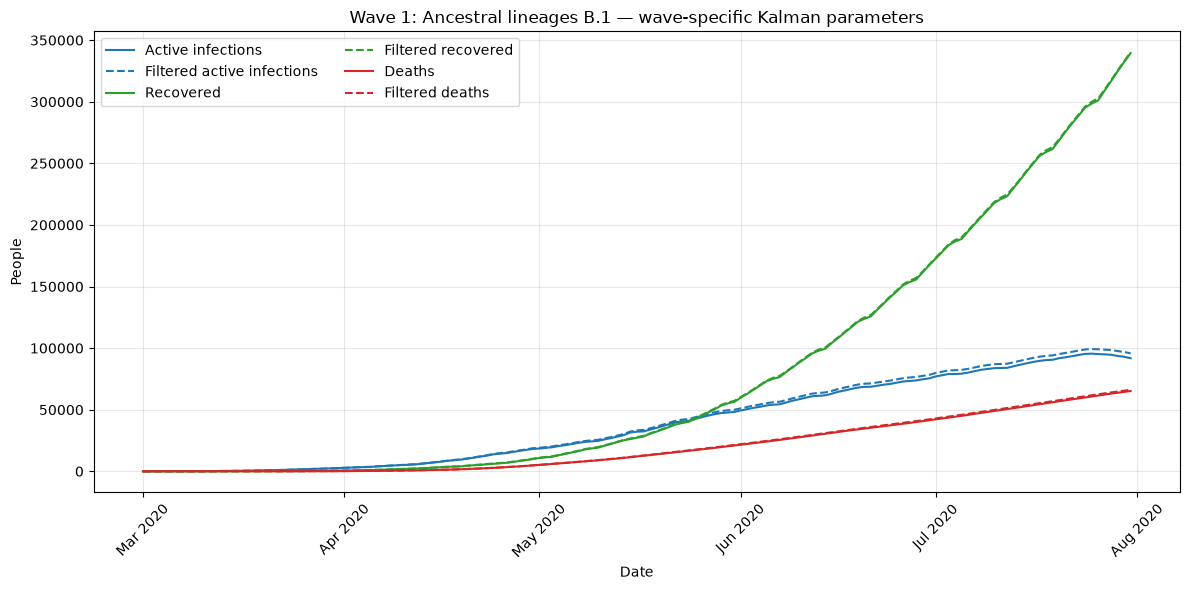

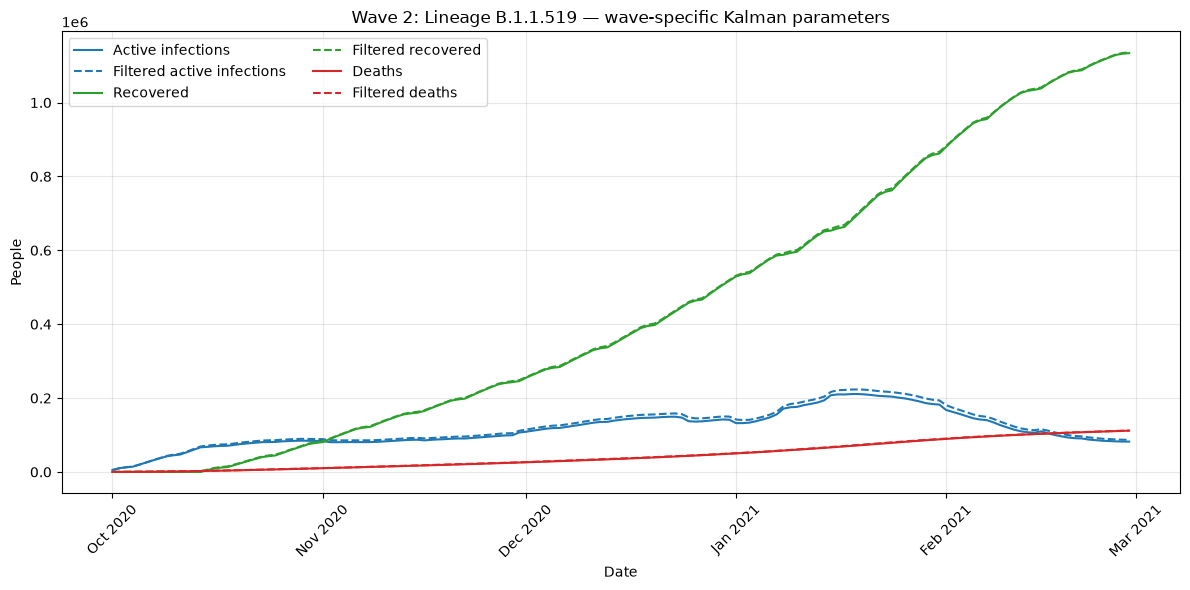

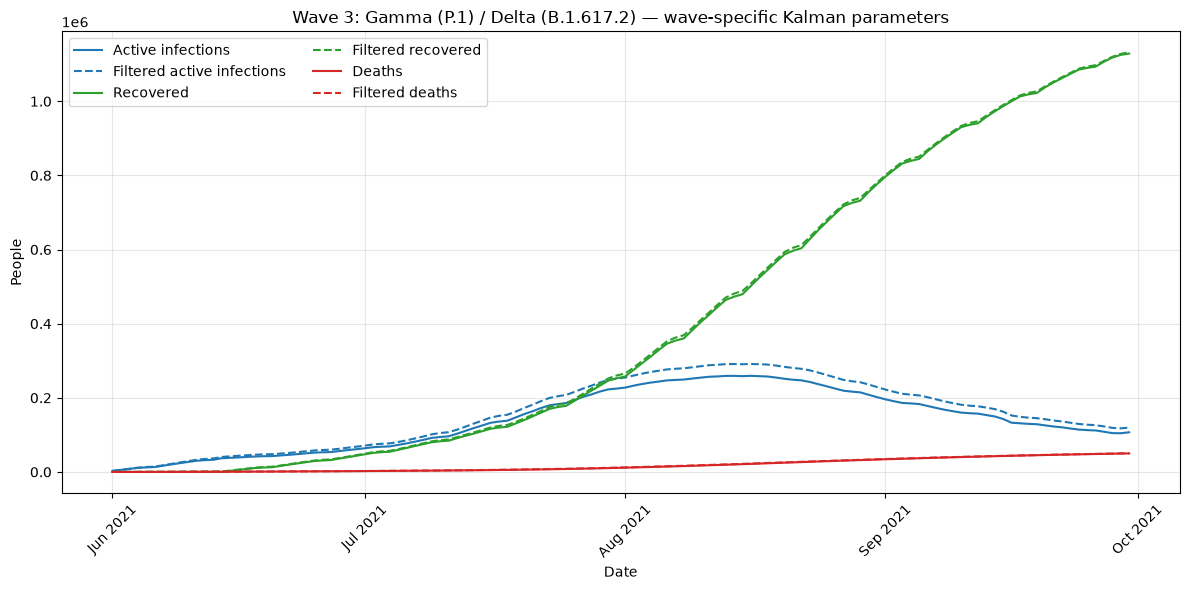

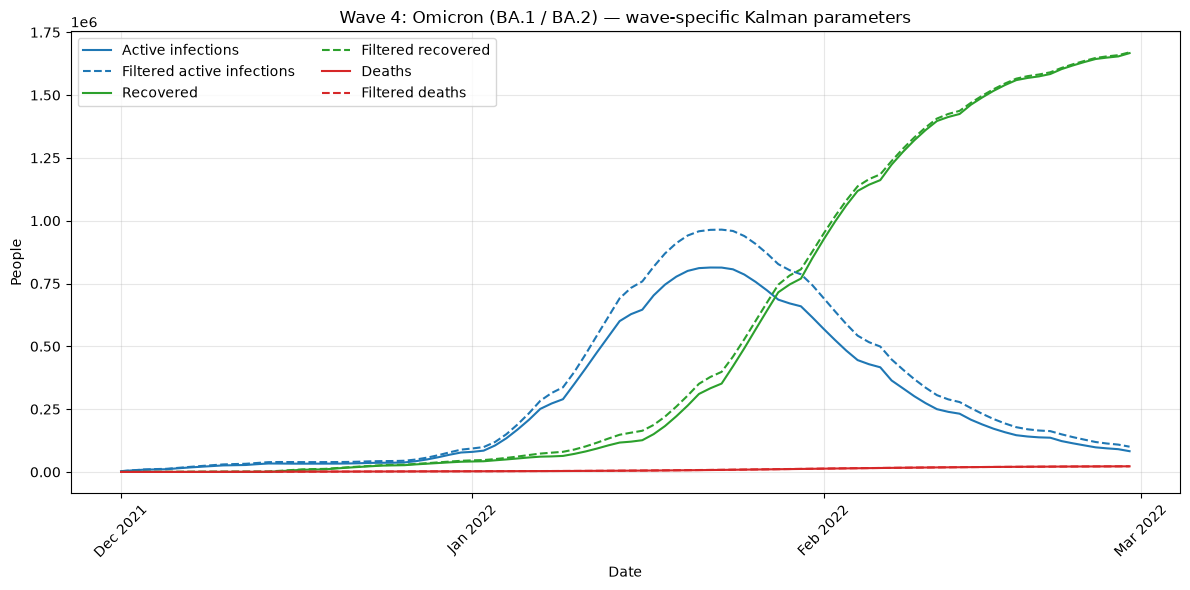

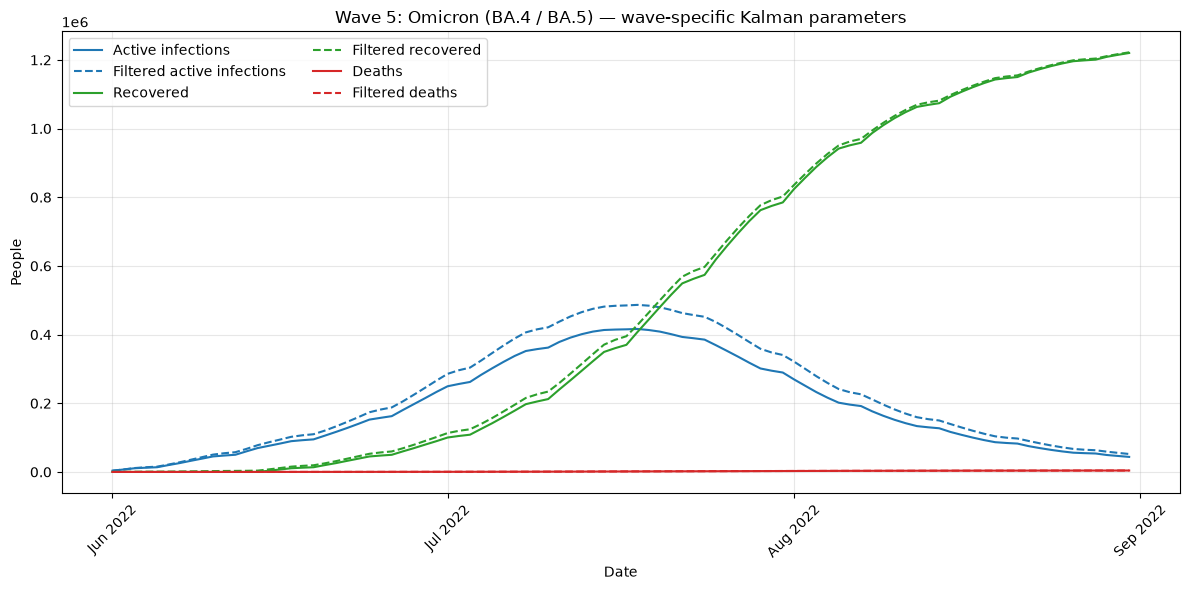

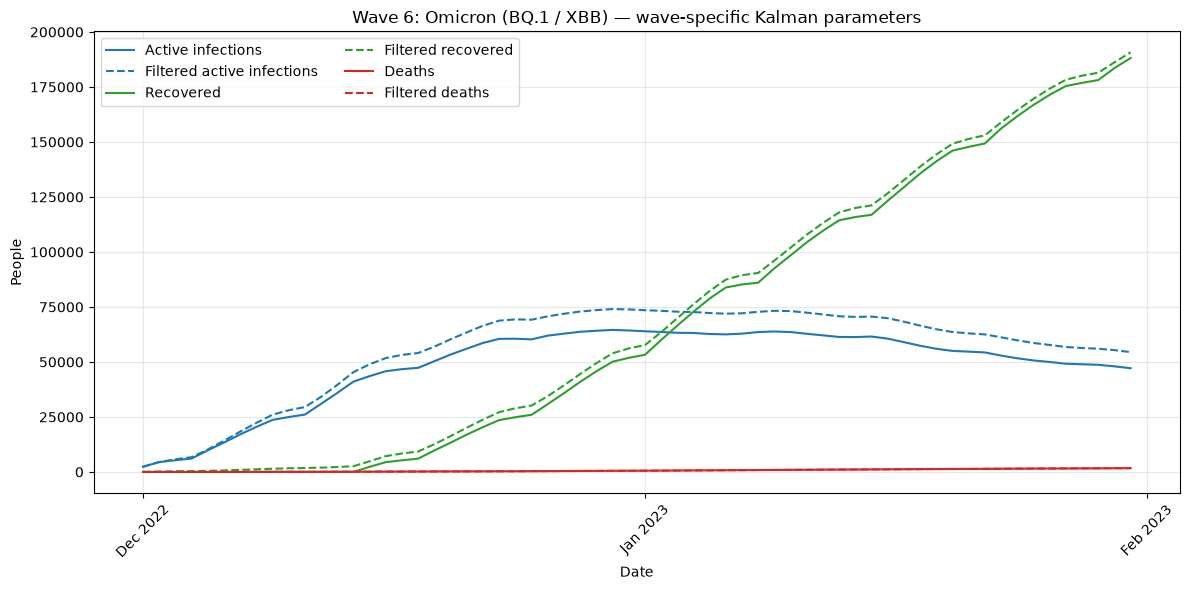

In [5]:
for wave in WAVES:
    name = wave["name"]
    observed = results[name]["observed"]
    filtered = results[name]["filtered"]
    fig, ax = plt.subplots(figsize=(12, 6))
    colors = {"I": "tab:blue", "R": "tab:green", "D": "tab:red"}
    observed_labels = {"I": "Active infections", "R": "Recovered", "D": "Deaths"}
    filtered_labels = {"I": "Filtered active infections", "R": "Filtered recovered", "D": "Filtered deaths"}
    for column in ["I", "R", "D"]:
        ax.plot(observed.index, observed[column], color=colors[column], label=observed_labels[column])
        ax.plot(filtered.index, filtered[f"{column}_filtered"], color=colors[column], linestyle="--", label=filtered_labels[column])
    ax.set_title(f"{name}: {wave['variant']} — wave-specific Kalman parameters")
    ax.set_xlabel("Date")
    ax.set_ylabel("People")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()

## Simulation summary

In [6]:
summary = pd.DataFrame([{
    "Wave": wave["name"], "Variant": wave["variant"],
    "Start": wave["start"], "End": wave["end"],
    "Records": results[wave["name"]]["records"],
    "beta": wave["beta"], "gamma": wave["gamma"], "delta": wave["delta"],
    "Calculated R0": wave["calculated_r0"],
    "Final filtered active infections": round(results[wave["name"]]["filtered"]["I_filtered"].iloc[-1], 2),
    "Final filtered recovered": round(results[wave["name"]]["filtered"]["R_filtered"].iloc[-1], 2),
    "Final filtered deaths": round(results[wave["name"]]["filtered"]["D_filtered"].iloc[-1], 2),
} for wave in WAVES])
summary.round(4)

,Wave,Variant,Start,End,Records,beta,gamma,delta,Calculated R0,Final filtered active infections,Final filtered recovered,Final filtered deaths
0,Wave 1,Ancestral lineages B.1,2020-03-01,2020-07-31,496402,0.3302,0.1046,0.0386,2.3063,95747.33,340158.98,66144.59
1,Wave 2,Lineage B.1.1.519,2020-10-01,2021-02-28,1327809,0.4250,0.1350,0.0200,2.7419,87097.10,1136051.90,112164.56
2,Wave 3,Gamma (P.1) / Delta (B.1.617.2),2021-06-01,2021-09-30,1285741,0.7250,0.1600,0.0115,4.2274,119714.74,1132108.58,50333.05
3,Wave 4,Omicron (BA.1 / BA.2),2021-12-01,2022-02-28,1771962,1.3500,0.2650,0.0020,5.0562,100559.77,1670148.53,22458.31
4,Wave 5,Omicron (BA.4 / BA.5),2022-06-01,2022-08-31,1268106,1.1000,0.2600,0.0010,4.2146,52286.26,1222108.17,4179.74
5,Wave 6,Omicron (BQ.1 / XBB),2022-12-01,2023-01-31,237016,1.0000,0.2900,0.0006,3.4406,54480.89,190749.79,1720.21
